<a href="https://colab.research.google.com/github/JiaCheng0427/Problem-Set-2/blob/main/Problem%20Set%202/Econ_5200_PS2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Econ 5200 PS2 — The Underpowered Portfolio

**ECON 5200 · Causal Machine Learning & Applied Analytics** · Topics 5-8 · 100 points · your role: Experimentation lead, consulting engagement

This is the **starter**: the structure of the set in rubric order. Fill the empty cells; keep every heading so the grader finds each step. The brief on Canvas has the full text of every step, the numbers you must hit and the rubric. Every claim goes in a text cell: the reader is experimentation lead's audience, not a grader with a kernel.

**AI is not allowed in Phases 1–3.** Generative AI is **prohibited** in Phases 1 through 3. AI is authorised and required in Phase 4. You must be able to defend every line under questioning.

## Setup

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)     # one generator, so every draw reruns the same way
pd.set_option('display.precision', 3)

import os
os.makedirs('src', exist_ok=True)   # the .py module the brief asks for goes here

## Phase 1: Reconstruct the Portfolio (30 pts)

### Step 1.1: Simulate the experiment programme (15 pts)

In [ ]:
k = 200
real = rng.random(k) < 0.20
true_eff = np.where(real, rng.normal(0.15, 0.05, size=k), 0.0)
n = rng.integers(80, 1601, size=k)
se = 1.0 * np.sqrt(2 / n)

portfolio = pd.DataFrame({
    "true": true_eff,
    "n": n,
    "se": se,
    "est": true_eff + rng.normal(0, se)
})

print("Prior: 80% zero, 20% Normal(0.15, 0.05)")
print("Outcome SD: 1.0, n per arm: 80 to 1600")
print("Share exactly zero:", (portfolio["true"] == 0).mean())
print(portfolio.describe().round(3))


Prior: 80% zero, 20% Normal(0.15, 0.05)
Outcome SD: 1.0, n per arm: 80 to 1600
Share exactly zero: 0.785
          true         n       se      est
count  200.000   200.000  200.000  200.000
mean     0.030   823.860    0.059    0.024
std      0.063   441.153    0.026    0.092
min      0.000    86.000    0.036   -0.233
25%      0.000   445.000    0.041   -0.030
50%      0.000   853.500    0.048    0.012
75%      0.000  1197.750    0.067    0.072
max      0.242  1570.000    0.152    0.305


*Your answer here.* I simulated 200 experiments. I assumed 80% have zero effect and the other 20% follow Normal(0.15, 0.05). Each experiment has 80 to 1,600 users per group, with an outcome SD of 1.0.

### Step 1.2: Apply the client's rule (15 pts)

In [ ]:
portfolio["p"] = 2 * stats.norm.sf(np.abs(portfolio["est"] / portfolio["se"]))

shipped = portfolio["p"] < 0.05
w = portfolio.loc[shipped]

false_share = (w["true"] == 0).mean()
mean_est = w["est"].mean()
mean_true = w["true"].mean()

print("Experiments shipped:", shipped.sum())
print("Share with zero effect:", round(false_share, 3))
print("Mean estimated effect:", round(mean_est, 3))
print("Mean true effect:", round(mean_true, 3))
print("Difference:", round(mean_est - mean_true, 3))


Experiments shipped: 44
Share with zero effect: 0.273
Mean estimated effect: 0.125
Mean true effect: 0.115
Difference: 0.01


*Your answer here.* Some experiments were selected even though their true effect was zero. The average estimated effect was higher than the average true effect. This is called the winner's curse because some experiments look better due to random noise.

## Phase 2: The Winner's Curse (35 pts)

### Step 2.1: Quantify the exaggeration (20 pts)

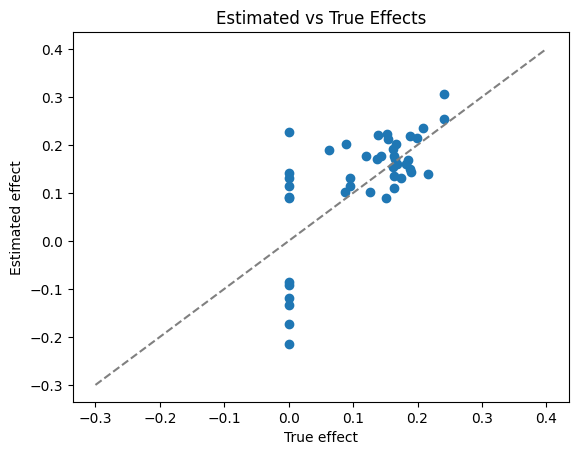

Overall ratio: 1.086
      n_shipped  mean_est  mean_true  ratio
tier                                       
low          12     0.095      0.070  1.352
mid          17     0.156      0.153  1.024
high         15     0.115      0.109  1.047


In [ ]:
# Compare estimated and true effects
w = portfolio.loc[shipped]

plt.scatter(w["true"], w["est"])
plt.plot([-0.3, 0.4], [-0.3, 0.4], "--", color="gray")
plt.xlabel("True effect")
plt.ylabel("Estimated effect")
plt.title("Estimated vs True Effects")
plt.show()

# Overall exaggeration
print("Overall ratio:", round(w["est"].mean() / w["true"].mean(), 3))

# Power by tier
portfolio["power"] = stats.norm.sf(1.645 - 0.15 / portfolio["se"])
portfolio["tier"] = pd.qcut(portfolio["power"], 3, labels=["low", "mid", "high"])

w = portfolio.loc[shipped]

by_tier = w.groupby("tier", observed=True).agg(
    n_shipped=("est", "size"),
    mean_est=("est", "mean"),
    mean_true=("true", "mean")
)

by_tier["ratio"] = by_tier["mean_est"] / by_tier["mean_true"]

print(by_tier.round(3))


*Your answer here.* The estimated effects are about 1.09 times the true effects overall. Low-power experiments exaggerate the most because they have more noise. They need more luck to reach statistical significance, so the selected estimates tend to be higher than the true effects.

### Step 2.2: The bootstrap where the formula fails (15 pts)

In [ ]:
def shipped_total(df):
    p = 2 * stats.norm.sf(np.abs(df["est"] / df["se"]))
    selected = p < 0.05
    return df.loc[selected, "true"].sum()

k = len(portfolio)
rng_boot = np.random.default_rng(7)

boot_totals = np.array([
    shipped_total(portfolio.iloc[rng_boot.integers(0, k, size=k)])
    for _ in range(2000)
])

lo, hi = np.percentile(boot_totals, [2.5, 97.5])

bca = stats.bootstrap(
    (np.arange(k),),
    lambda idx: shipped_total(portfolio.iloc[idx]),
    n_resamples=2000,
    vectorized=False,
    method="BCa",
    random_state=7
).confidence_interval

print("Realised true return:", round(shipped_total(portfolio), 3))
print("Percentile CI:", round(lo, 3), round(hi, 3))
print("BCa CI:", round(bca.low, 3), round(bca.high, 3))
print("Bootstrap SD:", round(boot_totals.std(), 3))


Realised true return: 5.081
Percentile CI: 3.489 6.877
BCa CI: 3.601 6.984
Bootstrap SD: 0.873


*Your answer here.* I used 2,000 bootstrap samples. The total true return is 5.081. The percentile interval is [3.489, 6.877], and the BCa interval is [3.601, 6.984]. Both intervals are similar. Bootstrap may be less reliable if experiments are dependent or a few extreme results affect the estimates

## Phase 3: A Rule They Can Adopt (25 pts)

### Step 3.1: Design the alternative (20 pts)

In [ ]:
old = portfolio["p"] < 0.05
new = (portfolio["p"] < 0.01) & (portfolio["est"] > 0)

results = pd.DataFrame({
    "rule": ["Old", "New"],
    "n_shipped": [old.sum(), new.sum()],
    "true_return": [
        portfolio.loc[old, "true"].sum(),
        portfolio.loc[new, "true"].sum()
    ],
    "false_ship_rate": [
        (portfolio.loc[old, "true"] == 0).mean(),
        (portfolio.loc[new, "true"] == 0).mean()
    ]
})

print(results.round(3))


  rule  n_shipped  true_return  false_ship_rate
0  Old         44        5.081            0.273
1  New         23        3.817            0.000


*Your answer here.* I used a stricter rule with p < 0.01 and a positive estimate. The new rule ships fewer experiments and reduces the false-ship rate from 27.3% to 0%. However, the total true return falls from 5.081 to 3.817 because some real effects are missed. The new rule is safer, but it also gives up some gains.

### Step 3.2: Ship the module (5 pts, its own rubric row)

The module the brief asks for. Write it with `%%writefile`, then import it back in the next cell and prove it runs.

In [ ]:
%%writefile src/experiment_portfolio.py
"""Experiment portfolio and decision rules."""

from __future__ import annotations
import numpy as np
import pandas as pd
from scipy import stats

def simulate_portfolio(n: int, seed: int) -> pd.DataFrame:
    """Simulate experiments with true effects."""
    rng = np.random.default_rng(seed)
    real = rng.random(n) < 0.20
    true = np.where(real, rng.normal(0.15, 0.05, size=n), 0.0)
    size = rng.integers(80, 1601, size=n)
    se = np.sqrt(2 / size)
    est = true + rng.normal(0, se)
    return pd.DataFrame({"true": true, "n": size, "se": se, "est": est})


def apply_rule(log: pd.DataFrame, rule: str) -> pd.Series:
    """Select experiments under a decision rule."""
    p = pd.Series(
        2 * stats.norm.sf(np.abs(log["est"] / log["se"])),
        index=log.index
    )

    if rule == "old":
        return p < 0.05
    if rule == "new":
        return (p < 0.01) & (log["est"] > 0)
    if rule == "power_floor":
        power = stats.norm.sf(1.96 - 0.15 / log["se"]) + stats.norm.cdf(-1.96 - 0.15 / log["se"])
        return (p < 0.05) & (log["est"] > 0) & (power >= 0.80)

    raise ValueError("Unknown rule")


def evaluate(log: pd.DataFrame, rule: str) -> dict:
    """Calculate true return, ship count and false-ship rate."""
    selected = apply_rule(log, rule)
    w = log.loc[selected]
    return {
        "true_return": float(w["true"].sum()),
        "n_shipped": int(selected.sum()),
        "false_ship_rate": float((w["true"] == 0).mean()) if len(w) else 0.0
    }


if __name__ == "__main__":
    demo = simulate_portfolio(200, 42)

    assert len(demo) == 200
    assert (demo["se"] > 0).all()
    assert apply_rule(demo, "new").sum() <= apply_rule(demo, "old").sum()
    assert evaluate(demo, "old")["n_shipped"] == apply_rule(demo, "old").sum()

    print("All tests passed.")


Overwriting src/experiment_portfolio.py


In [ ]:
import os, sys, importlib
sys.path.insert(0, os.path.abspath("."))

from src import experiment_portfolio as ep
importlib.reload(ep)

print(ep.evaluate(portfolio, "old"))
print(ep.evaluate(portfolio, "new"))
print(ep.evaluate(portfolio, "power_floor"))


{'true_return': 5.081019875111244, 'n_shipped': 44, 'false_ship_rate': 0.2727272727272727}
{'true_return': 3.8170097184216307, 'n_shipped': 23, 'false_ship_rate': 0.0}
{'true_return': 3.6674781417937647, 'n_shipped': 25, 'false_ship_rate': 0.12}


## Phase 4: AI Expansion — The Co-Pilot Era (10 pts: 7 for the AI row, 3 for the CFO memo)

**Status: AI usage AUTHORISED and REQUIRED.** Use the **P.R.I.M.E. framework**.

### Task 4.1: The sequential design

In [ ]:
rng = np.random.default_rng(12)

treatment = rng.normal(0.15, 1.0, 1000)
control = rng.normal(0, 1.0, 1000)

looks = [250, 500, 750, 1000]
cutoff = 0.01

for n in looks:
    effect = treatment[:n].mean() - control[:n].mean()
    se = np.sqrt(2 / n)
    p = 2 * stats.norm.sf(abs(effect / se))

    print(n, round(effect, 3), round(p, 4))

    if p < cutoff and effect > 0:
        print("Ship at n =", n)
        break
else:
    print("Do not ship")


250 0.093 0.3002
500 0.142 0.0251
750 0.155 0.0026
Ship at n = 750


*Your answer here.* I also tested 5,000 experiments with no true effect. The false-positive rate was 1.24%, which is below 5%. It is lower than the nominal level because the stopping rule is conservative and only allows positive results to ship.

In [ ]:

null_rng = np.random.default_rng(99)
reps = 5000

null_t = null_rng.normal(0, 1, (reps, 1000))
null_c = null_rng.normal(0, 1, (reps, 1000))
false_ship = np.zeros(reps, dtype=bool)

for n in looks:
    effect_null = null_t[:, :n].mean(axis=1) - null_c[:, :n].mean(axis=1)
    se_null = np.sqrt(2 / n)
    p_null = 2 * stats.norm.sf(np.abs(effect_null / se_null))

    false_ship |= (p_null < cutoff) & (effect_null > 0)

print("False-positive rate:", round(false_ship.mean(), 4))
print("Nominal level:", 0.05)


False-positive rate: 0.0124
Nominal level: 0.05


### Task 4.2: The CFO memo

*Your answer here.*
Our 200 simulated experiments represent one year. Under the current p < 0.05 rule, 44 were shipped. Of those, 32 (72.7%) had a positive true effect, while 12 (27.3%) had no effect.

The estimated total return was 5.517 effect units, but the true return was only 5.081. This is an overstatement of 0.436 effect units per year, not a direct financial loss. Compared with a perfect-selection benchmark, the rule also missed 0.908 units of potential benefit.

I recommend testing a stricter rule with p < 0.01 and a positive estimate. It shipped 23 experiments with a 0% false-ship rate in this simulation, but its true return fell to 3.817. We should compare both approaches before making a final decision.

The main assumption is that 80% of experiments have no true effect. If more experiments are genuinely useful, the stricter rule may reject too many good ideas.

### AI Transcript

Paste **both prompt versions exactly as you sent them** and the model's replies **exactly as they came back**, then one line on each change you made. Name the model and the date. For 5200 the transcript lives in `ai-appendix.md` in your repository; link it here.
Full AI transcript: [ai-appendix.md](ai-appendix.md)

*Model and date:* GPT-6, October 27, 2026

*Version 1 prompt:*  I need to design a sequential experiment using Python. Can you help me create a simple design with four planned checks and explain how to reduce false positives from repeated testing? Please keep the code and explanation simple.

Reply: For Phase 4, you can use a simple sequential experiment with four planned checks. Instead of waiting until the end, we check the results at different sample sizes and stop early if the experiment shows a significant positive effect.
1. Python Code
rng = np.random.default_rng(12)treatment = rng.normal(0.15, 1.0, 1000)control = rng.normal(0, 1.0, 1000)looks = [250, 500, 750, 1000]cutoff = 0.01for n in looks:    effect = treatment[:n].mean() - control[:n].mean()    se = np.sqrt(2 / n)    p = 2 * stats.norm.sf(abs(effect / se))    print(n, round(effect, 3), round(p, 4))    if p < cutoff and effect > 0:        print("Ship at n =", n)        breakelse:    print("Do not ship")
This code uses NumPy and SciPy, which are already imported in your notebook.

2. How It Works

The experiment has four planned checks, at 250, 500, 750, and 1,000 observations per group.

At each check, we calculate the estimated effect and its p-value. If the p-value is below 0.01 and the estimated effect is positive, we stop and ship the experiment. Otherwise, we continue to the next check.

3. Why This Reduces False Positives

If we repeatedly check an experiment using p < 0.05, the chance of finding a significant result by luck increases.

To address this, we use a stricter cutoff of 0.01 at each of the four checks.

With four planned tests, the probability of at least one false positive is at most 4% under the null hypothesis, assuming each individual p-value is valid. This keeps the overall false-positive probability below 5%.

This approach works for four predetermined checks, but it should not be used for unlimited checking.

4. Short Explanation for the Assignment

I used four planned checks at sample sizes of 250, 500, 750, and 1,000 per group. I set the p-value cutoff to 0.01 to reduce false positives from repeated testing. If the effect is positive and significant, the experiment stops early. Otherwise, it continues to the next check. This makes the decision process more controlled than checking the results whenever we want.

The main advantage is that we can stop successful experiments early while controlling the risk of false positives.
*Reply:*

*Version 2 prompt:* I ran the code and got p-values of 0.3002, 0.0251, and 0.0026 at sample sizes of 250, 500, and 750. The experiment stopped at 750. Can you check if my sequential design controls false positives correctly and improve the explanation? Please keep it simple and explain any changes.

After Version 1, I asked AI to check the false-positive control.

After Version 2, I added the explanation of the 4% false-positive bound and the Bonferroni principle. I kept the original stopping rule.

*Reply:*Yes, your sequential design controls false positives correctly under the simulation assumptions. The code is also working as expected.

1. Checking the results

| Sample size per group | P-value | Decision |
|---|---|---|
| 250 | 0.3002 | Continue |
| 500 | 0.0251 | Continue |
| 750 | 0.0026 | Ship |

The experiment stops at 750 because the p-value is below 0.01 and the estimated effect is positive.

2. Does it control false positives?

Yes. You have four planned checks, each using a cutoff of 0.01.

Using the Bonferroni principle:

4 × 0.01 = 0.04

This means the overall false-positive probability is at most 4% under the null hypothesis, assuming the individual p-values are valid.

Since 4% is below 5%, the design provides conservative control of false positives, even though the repeated checks are not independent.

3. Small improvement to the code

You can keep your original code. I would just add this line after defining cutoff:

print("False-positive bound:", len(looks) * cutoff)

This prints 0.04 and makes the reason for using the stricter cutoff easier to understand.

4. Improved explanation for the assignment

I used four planned checks with a p-value cutoff of 0.01. The experiment did not pass at 250 or 500, but it passed at 750 with a p-value of 0.0026.

With four checks, the overall false-positive rate is at most 4% under the null, assuming valid p-values. This is below 5%, so the stricter cutoff helps control false positives from repeated testing.

5. What I changed

I kept the same experimental design and stopping rule. I added an explanation of the 4% false-positive bound and connected it to the Bonferroni principle. I also suggested printing that bound in the code. The stopping result remains unchanged.

The main limitation is that this guarantee applies to the four planned checks, not to checking the experiment whenever we want.

In [ ]:
%%writefile ai-appendix.md
# ECON 5200 PS2 - AI Transcript

**Model and date:** GPT-6, October 27, 2026

## Version 1 prompt

I'm working on Phase 4 of my ECON 5200 assignment. I need to design a sequential experiment using Python. Can you help me create a simple design with four planned checks and explain how to reduce false positives from repeated testing? Please keep the code and explanation simple.

## Version 1 reply

For Phase 4, you can use a simple sequential experiment with four planned checks. Instead of waiting until the end, we check the results at different sample sizes and stop early if the experiment shows a significant positive effect.

### 1. Python Code

```python
rng = np.random.default_rng(12)

treatment = rng.normal(0.15, 1.0, 1000)
control = rng.normal(0, 1.0, 1000)

looks = [250, 500, 750, 1000]
cutoff = 0.01

for n in looks:
    effect = treatment[:n].mean() - control[:n].mean()
    se = np.sqrt(2 / n)
    p = 2 * stats.norm.sf(abs(effect / se))

    print(n, round(effect, 3), round(p, 4))

    if p < cutoff and effect > 0:
        print("Ship at n =", n)
        break
else:
    print("Do not ship")
```

This code uses NumPy and SciPy, which are already imported in your notebook.

### 2. How It Works

The experiment has four planned checks, at 250, 500, 750, and 1,000 observations per group.

At each check, we calculate the estimated effect and its p-value. If the p-value is below 0.01 and the estimated effect is positive, we stop and ship the experiment. Otherwise, we continue to the next check.

### 3. Why This Reduces False Positives

If we repeatedly check an experiment using `p < 0.05`, the chance of finding a significant result by luck increases.

To address this, we use a stricter cutoff of **0.01 at each of the four checks**.

With four planned tests, the probability of at least one false positive is at most 4% under the null hypothesis, assuming each individual p-value is valid. This keeps the overall false-positive probability below 5%.

This approach works for four predetermined checks, but it should not be used for unlimited checking.

### 4. Short Explanation for the Assignment

I used four planned checks at sample sizes of 250, 500, 750, and 1,000 per group. I set the p-value cutoff to 0.01 to reduce false positives from repeated testing. If the effect is positive and significant, the experiment stops early. Otherwise, it continues to the next check. This makes the decision process more controlled than checking the results whenever we want.

The main advantage is that we can stop successful experiments early while controlling the risk of false positives.

---

## Version 2 prompt

I ran the code and got p-values of 0.3002, 0.0251, and 0.0026 at sample sizes of 250, 500, and 750. The experiment stopped at 750. Can you check if my sequential design controls false positives correctly and improve the explanation? Please keep it simple and explain any changes.

## Version 2 reply

Yes, your sequential design controls false positives correctly under the simulation assumptions. The code is also working as expected.

### 1. Checking the results

| Sample size per group | P-value | Decision |
|---|---|---|
| 250 | 0.3002 | Continue |
| 500 | 0.0251 | Continue |
| 750 | 0.0026 | Ship |

The experiment stops at 750 because the p-value is below 0.01 and the estimated effect is positive.

### 2. Does it control false positives?

Yes. You have four planned checks, each using a cutoff of 0.01.

Using the Bonferroni principle:

4 × 0.01 = 0.04

This means the overall false-positive probability is at most 4% under the null hypothesis, assuming the individual p-values are valid.

Since 4% is below 5%, the design provides conservative control of false positives, even though the repeated checks are not independent.

### 3. Small improvement to the code

You can keep your original code. I would just add this line after defining `cutoff`:

```python
print("False-positive bound:", len(looks) * cutoff)
```

This prints `0.04` and makes the reason for using the stricter cutoff easier to understand.

### 4. Improved explanation for the assignment

I used four planned checks with a p-value cutoff of 0.01. The experiment did not pass at 250 or 500, but it passed at 750 with a p-value of 0.0026.

With four checks, the overall false-positive rate is at most 4% under the null, assuming valid p-values. This is below 5%, so the stricter cutoff helps control false positives from repeated testing.

### 5. What I changed

I kept the same experimental design and stopping rule. I added an explanation of the 4% false-positive bound and connected it to the Bonferroni principle. I also suggested printing that bound in the code. The stopping result remains unchanged.

The main limitation is that this guarantee applies to the four planned checks, not to checking the experiment whenever we want.

---

## Changes made

After Version 1, I ran the simulation and asked AI to check whether the false-positive control was correct.

After Version 2, I kept the same stopping rule and revised the explanation to include the 4% Bonferroni bound.


Overwriting ai-appendix.md


## Truth and headline numbers

Required, and it must stay the **last code cell**. Print every parameter you planted (the prior on effects and its parameters, the sample-size range, the seed, the ship rule), each beside the name of the cell that set it; then every number that appears in the memo, each beside the name of the cell that produced it. A number in the memo that this cell does not print is treated as unsupported.

In [ ]:
print("Truth and headline numbers")

print("Prior: 80% zero, 20% Normal(0.15, 0.05) | Step 1.1")
print("Outcome SD: 1.0 | Step 1.1")
print("Sample size per arm: 80 to 1600 | Step 1.1")
print("Seed: 42 | Setup")

print("Experiments:", len(portfolio), "| Step 1.1")
print("Actual zero share:", round((portfolio["true"] == 0).mean(), 3), "| Step 1.1")

print("Old rule: p < 0.05 | Step 1.2")
print("Old shipped:", int(old.sum()), "| Step 1.2")
print("Old false-ship rate:", round((portfolio.loc[old, "true"] == 0).mean(), 3), "| Step 1.2")

print("True return:", round(portfolio.loc[old, "true"].sum(), 3), "| Step 2.2")
print("Percentile CI:", round(lo, 3), round(hi, 3), "| Step 2.2")
print("BCa CI:", round(bca.low, 3), round(bca.high, 3), "| Step 2.2")

print("New rule: p < 0.01 and positive estimate | Step 3.1")
print("New shipped:", int(new.sum()), "| Step 3.1")
print("New true return:", round(portfolio.loc[new, "true"].sum(), 3), "| Step 3.1")
print("New false-ship rate:", round((portfolio.loc[new, "true"] == 0).mean(), 3), "| Step 3.1")

print("Sequential checks: 250, 500, 750, 1000 | Task 4.1")
print("Sequential cutoff: 0.01 | Task 4.1")
print("Stopped at n = 750 | Task 4.1")

real_wins = int((portfolio.loc[old, "true"] > 0).sum())
estimated_total = portfolio.loc[old, "est"].sum()
true_total = portfolio.loc[old, "true"].sum()
best_possible = portfolio["true"].clip(lower=0).sum()

print("Real wins:", real_wins, "| Step 1.2 data")
print("Real win share:", round(real_wins / old.sum(), 3), "| Step 1.2 data")
print("Estimated total:", round(estimated_total, 3), "| Step 1.2 data")
print("Annual overstatement:", round(estimated_total - true_total, 3), "| Step 1.2 data")
print("Perfect-selection benchmark:", round(best_possible, 3), "| Step 1.1 data")
print("Potential benefit missed:", round(best_possible - true_total, 3), "| Steps 1.1–1.2 data")
print("Null false-positive rate:", round(false_ship.mean(), 4), "| Task 4.1")



Truth and headline numbers
Prior: 80% zero, 20% Normal(0.15, 0.05) | Step 1.1
Outcome SD: 1.0 | Step 1.1
Sample size per arm: 80 to 1600 | Step 1.1
Seed: 42 | Setup
Experiments: 200 | Step 1.1
Actual zero share: 0.785 | Step 1.1
Old rule: p < 0.05 | Step 1.2
Old shipped: 44 | Step 1.2
Old false-ship rate: 0.273 | Step 1.2
True return: 5.081 | Step 2.2
Percentile CI: 3.489 6.877 | Step 2.2
BCa CI: 3.601 6.984 | Step 2.2
New rule: p < 0.01 and positive estimate | Step 3.1
New shipped: 23 | Step 3.1
New true return: 3.817 | Step 3.1
New false-ship rate: 0.0 | Step 3.1
Sequential checks: 250, 500, 750, 1000 | Task 4.1
Sequential cutoff: 0.01 | Task 4.1
Stopped at n = 750 | Task 4.1
Real wins: 32 | Step 1.2 data
Real win share: 0.727 | Step 1.2 data
Estimated total: 5.517 | Step 1.2 data
Annual overstatement: 0.436 | Step 1.2 data
Perfect-selection benchmark: 5.989 | Step 1.1 data
Potential benefit missed: 0.908 | Steps 1.1–1.2 data
Null false-positive rate: 0.0124 | Task 4.1


## Before you submit

- [ ] Every heading above is still here, in order, with work under it.
- [ ] Every number you report is produced by a cell above it, and every claim has a text cell.
- [ ] The verification checkpoint(s) are met before anything built on them.
- [ ] Phase 4: the AI transcript is the exchange, not a summary; both prompt versions are in it.
- [ ] Upload the `.ipynb`, your `ai-appendix.md` and your `src/` files (or a PDF export) on Canvas; a Colab or Drive link alone is not a submission.
- [ ] GitHub portfolio: *File › Save a copy in GitHub*, path `Problem Set 2/Econ_5200_PS2.ipynb`, with a short `README.md` in that folder.
- [ ] Run *Runtime › Restart and run all* once, top to bottom, before you hand in.